# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



Chi Square: 2.96
p-value: 0.94
Degrees of Freedom: 8
Expected: [[  7.28571429  12.08571429  24.51428571  17.05714286   2.05714286]
 [111.13605442 184.35510204 373.94013605 260.18911565  31.37959184]
 [ 51.57823129  85.55918367 173.54557823 120.7537415   14.56326531]]
Fail to reject the Null Hypothesis. There is no correlation between an employees education and department.


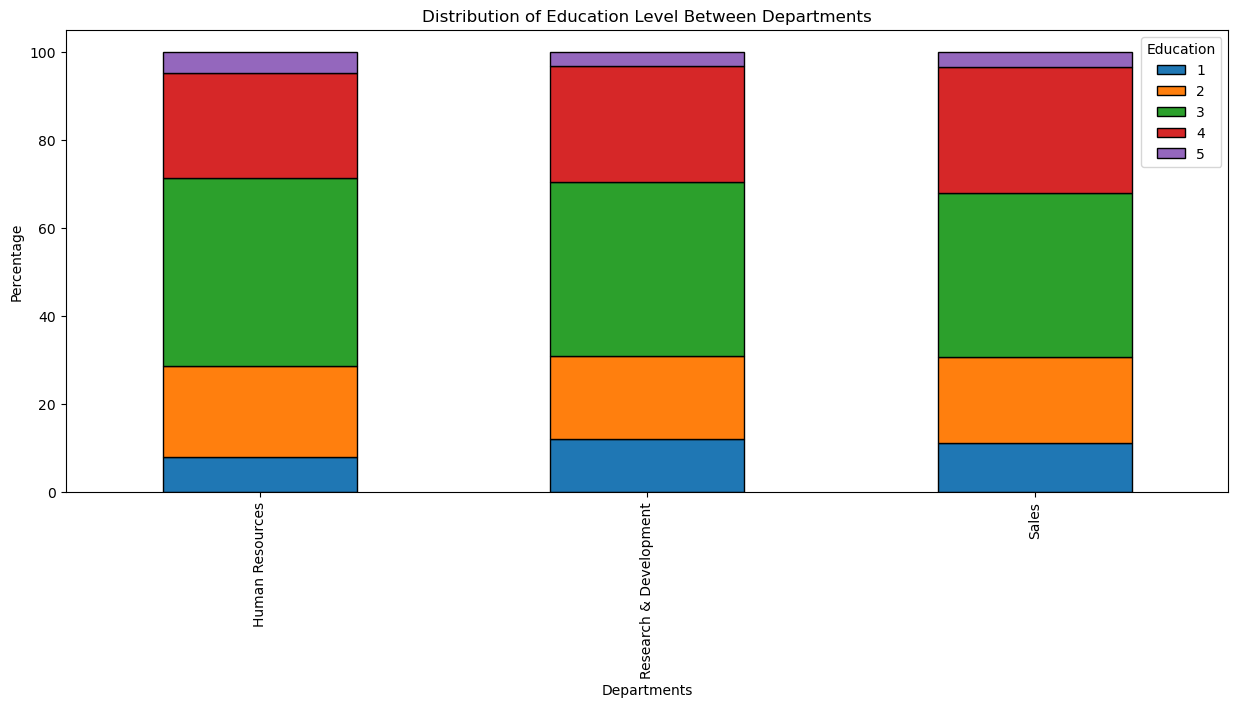

Since the p-value is much greater than 0.05, we fail to reject H0, meaning there isn't a correlation between the two categories.
For HR, this means that education is not a source for workplace imbalance and as such, things like promotion/pay should be checked for throygh different factors.


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare, chi2_contingency, stats

#PART 1
# Is an employee's department associated with their education level?
# Null Hypothesis: There is no correlation between department and education level
# Alternate Hypothesis: There is a correlation between department and education level
df = pd.read_csv('HR-Employee-Attrition.csv')
#df
table = pd.crosstab(df['Department'], df['Education'])
#print(table)
chi2, p, dof, expected = chi2_contingency(table)
print(f"Chi Square: {chi2:.2f}")
print(f"p-value: {p:.2f}")
print(f"Degrees of Freedom: {dof}")
print(f"Expected: {expected}")
if p > 0.05:
    print("Fail to reject the Null Hypothesis. There is no correlation between an employees education and department.")
else:
    print("Reject the Null Hypothesis. There is a correlation between an employees education and department.")

tablePercentage = pd.crosstab(df['Department'], df['Education'], normalize='index') * 100

tablePercentage.plot(kind='bar', stacked=True, figsize=(15,6), edgecolor='black')
plt.title('Distribution of Education Level Between Departments')
plt.xlabel('Departments')
plt.ylabel('Percentage')
plt.show()

print("Since the p-value is much greater than 0.05, we fail to reject H0, meaning there isn't a correlation between the two categories.")
print("For HR, this means that education is not a source for workplace imbalance and as such, things like promotion/pay should be checked for throygh different factors.")

F-Stat: 3.20
p-value: 0.04
Reject the Null Hypothesis. There is a difference between monthly income between the 3 departments.


/tmp/ipykernel_663/2149622826.py:8: DeprecationWarning: Please import `f_oneway` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  f_stat, p = stats.f_oneway(*groups)


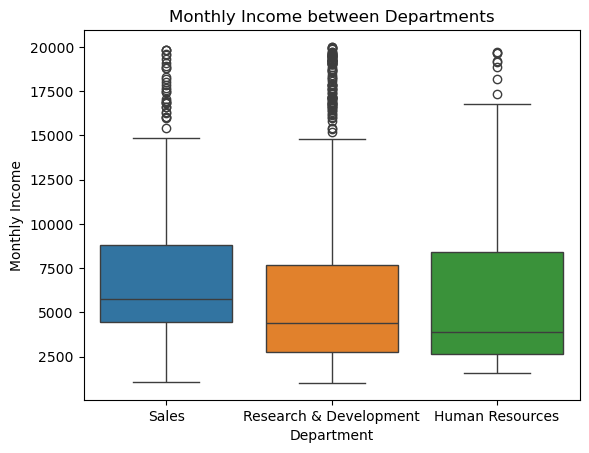

Since the p-value is less than 0.05, we reject the Null Hypothesis(H0). This means that the MonthlyIncome between the three departments are different.
For HR, this shows that departments are weak factor when it comes to pay and different factors are more likely to be the case when it comes to the difference.


In [24]:
# PART 2
# Does the mean MonthlyIncome differ between the 3 departments?
# Null Hypothesis(H0): The MonthlyIncome is the same between all 3 departments
# Alternate Hypothesis(H1): Two of the departments have different MonthlyIncome

# groups = [df.loc['Department'] == departmentName, 'MonthlyIncome'].values for departmentName in df.groupby('Department')
groups = [group['MonthlyIncome'].values for departmentName, group in df.groupby('Department')]
f_stat, p = stats.f_oneway(*groups)

print(f"F-Stat: {f_stat:.2f}")
print(f"p-value: {p:.2f}")
if p > 0.05:
    print("Fail to reject the Null Hypothesis. There is no difference between MonthlyIncome between the 3 departments")
else:
    print("Reject the Null Hypothesis. There is a difference between monthly income between the 3 departments.")

sns.boxplot(data=df, x="Department", y="MonthlyIncome", hue="Department")
plt.title("Monthly Income between Departments")
plt.xlabel("Department")
plt.ylabel("Monthly Income")
plt.show()

print("Since the p-value is less than 0.05, we reject the Null Hypothesis(H0). This means that the MonthlyIncome between the three departments are different.")
print("For HR, this shows that departments are weak factor when it comes to pay and different factors are more likely to be the case when it comes to the difference.")

In [ ]:
# PART 3
# Type 1 error (Rejecting H0 when it is true): HR concludes that there is a difference between education level in the departments even though there actually isn't
# Type 2 error (Failing to reject H0 when it is false): HR concludes there is no association when the departments do have a different education level
# A type 2 error carries a worse operational risk because a type 2 error could mean that the company promotes or pays on education unevenly. 